# Chapitre 5 - Cours 1 : réplication à leader unique

Répliquer, c'est garder une copie des mêmes données sur plusieurs machines reliées par
un réseau. Tant que les données ne changent pas, c'est trivial : on copie une fois. Toute
la difficulté vient des **modifications**. Ce premier cours étudie la famille la plus
répandue, la réplication à **leader unique** (leader-based, primary-backup,
active/passive) : un nœud reçoit toutes les écritures et les transmet aux autres. Il
couvre l'introduction du chapitre et la section *Leaders and Followers* jusqu'à
*Handling Node Outages* inclus.

**Plan.**

1. Trois raisons de répliquer, et le schéma leader-suiveurs.
2. Synchrone, asynchrone, semi-synchrone : latence et disponibilité des écritures.
3. Ajouter un suiveur sans arrêter le leader.
4. Panne d'un suiveur : le rattrapage.
5. Panne du leader : le basculement et les écritures perdues.
6. Split brain, fencing et clés réutilisées.

Les simulations reposent sur le simulateur à événements `ddia.sim` et sur le module
[`ddia/replication.py`](../../ddia/replication.py) (classes `ReplNode`, `Controller`,
`WriterClient`, fonction `failover_scenario`).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Trois raisons de répliquer (introduction du chapitre)

On réplique pour trois raisons, qui reviendront tout au long du chapitre :

- **latence** : garder les données près des utilisateurs (une réplique par continent) ;
- **disponibilité et durabilité** : continuer à servir, et ne rien perdre, quand une
  machine (ou tout un centre de données) tombe ;
- **débit de lecture** : multiplier les machines qui répondent aux lectures.

Ce chapitre suppose que chaque machine peut contenir **toute** la base ; découper une
base trop grosse est l'objet du chapitre 6. Il étudie trois familles
d'algorithmes, que presque toutes les bases distribuées utilisent : leader unique,
multi-leader et sans leader.

**Le schéma leader-suiveurs.** Une réplique est désignée **leader** (ou primaire) :
toutes les écritures des clients passent par elle. Elle les applique à son stockage
local puis les envoie aux autres répliques, les **suiveurs** (followers, réplicas de
lecture, secondaires), sous la forme d'un **journal de réplication** (flux de
changements). Chaque suiveur applique les écritures **dans le même ordre** que le leader.
Les lectures peuvent aller au leader ou à n'importe quel suiveur. C'est le fonctionnement
par défaut de PostgreSQL, MySQL, Oracle Data Guard, SQL Server, MongoDB, et aussi de
Kafka.

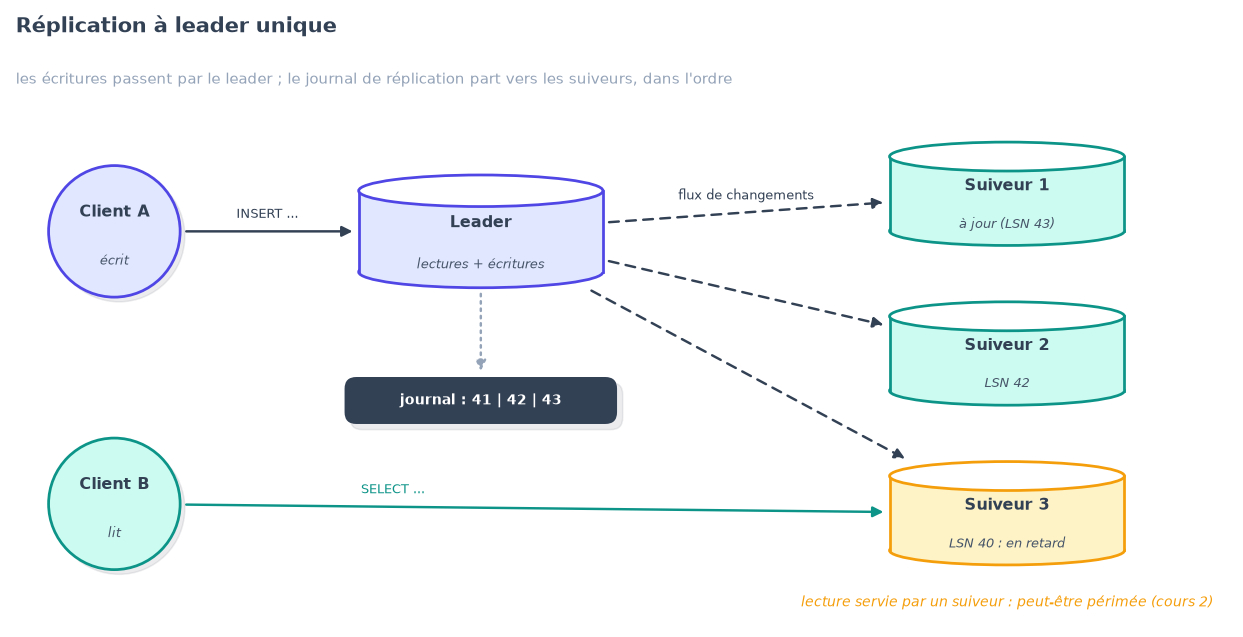

In [2]:
d = Diagram(13, 5.6, title="Réplication à leader unique",
            subtitle="les écritures passent par le leader ; le journal de réplication part vers les suiveurs, dans l'ordre")
d.box("w", 1.1, 4.2, "Client A", sub="écrit", kind="user", w=1.4, color=INDIGO)
d.box("r1", 1.1, 1.3, "Client B", sub="lit", kind="user", w=1.4, color=TEAL)
d.box("L", 5.0, 4.2, "Leader", sub="lectures + écritures", color=INDIGO, kind="db", w=2.6, h=1.2)
d.box("log", 5.0, 2.4, "journal : 41 | 42 | 43", color=SLATE, kind="tag", w=2.9, h=0.5, fontsize=9)
for i, (y, sub) in enumerate([(4.6, "à jour (LSN 43)"), (2.9, "LSN 42"), (1.2, "LSN 40 : en retard")]):
    d.box(f"f{i}", 10.6, y, f"Suiveur {i + 1}", sub=sub, color=[TEAL, TEAL, AMBER][i], kind="db", w=2.5, h=1.1)
    d.arrow("L", f"f{i}", "flux de changements" if i == 0 else None, style="dashed", color=SLATE)
d.arrow("w", "L", "INSERT ... ")
d.arrow("r1", "f2", "SELECT ...", color=TEAL, label_pos=0.3)
d.arrow("L", "log", style="dotted", color=GRAY)
d.note(10.6, 0.25, "lecture servie par un suiveur : peut-être périmée (cours 2)", color=AMBER)
d.show()

> **À retenir.** On réplique pour la latence, la disponibilité et le débit de lecture.
> Avec un leader unique, l'ordre des écritures est décidé à un seul endroit, puis
> recopié tel quel : c'est ce qui rend ce schéma simple à comprendre.

## 2. Synchrone ou asynchrone (section *Synchronous Versus Asynchronous Replication*)

Quand le leader répond-il « c'est enregistré » au client ?

- **synchrone** : après qu'un suiveur a confirmé avoir reçu l'écriture. Le suiveur est
  garanti à jour : si le leader meurt, rien n'est perdu ;
- **asynchrone** : tout de suite, sans attendre. Le leader n'est jamais ralenti par un
  suiveur, mais une écriture confirmée peut n'exister **que** sur le leader.

Le diagramme espace-temps ci-dessous montre une écriture avec un suiveur synchrone et un
suiveur asynchrone : le client attend l'acquittement du suiveur 1, pas celui du
suiveur 2, qui applique l'écriture bien plus tard.

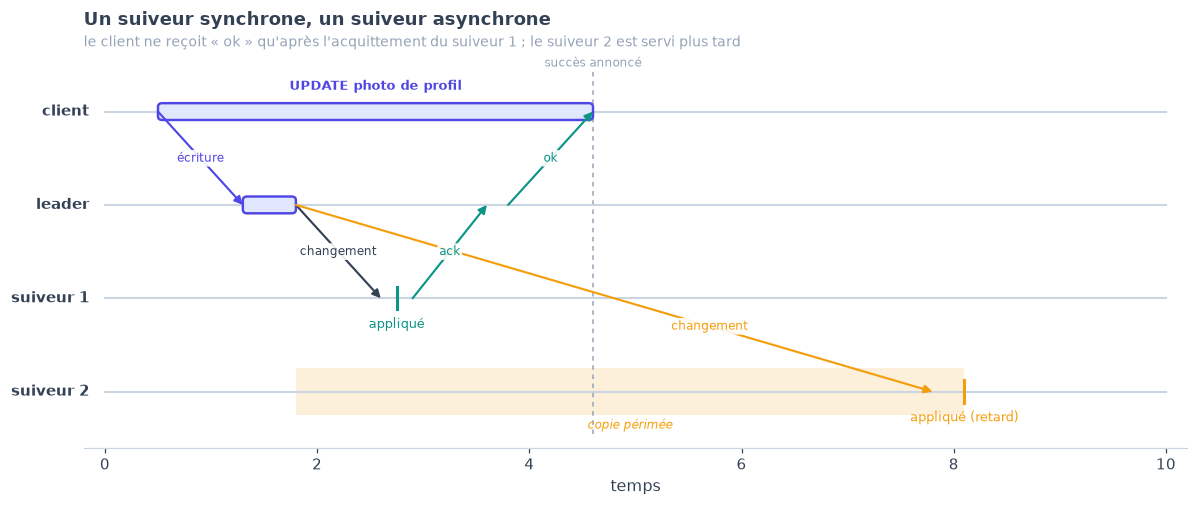

In [3]:
st = SpaceTime(["client", "leader", "suiveur 1", "suiveur 2"], t_max=10, width=11,
               title="Un suiveur synchrone, un suiveur asynchrone",
               subtitle="le client ne reçoit « ok » qu'après l'acquittement du suiveur 1 ; le suiveur 2 est servi plus tard")
st.op("client", 0.5, 4.6, "UPDATE photo de profil", color=INDIGO)
st.msg("client", 0.5, "leader", 1.3, "écriture", color=INDIGO)
st.op("leader", 1.3, 1.8, "", color=INDIGO)
st.msg("leader", 1.8, "suiveur 1", 2.6, "changement", color=SLATE)
st.msg("suiveur 1", 2.9, "leader", 3.6, "ack", color=TEAL)
st.msg("leader", 3.8, "client", 4.6, "ok", color=TEAL)
st.msg("leader", 1.8, "suiveur 2", 7.8, "changement", color=AMBER, label_pos=0.65)
st.event("suiveur 1", 2.75, "appliqué", kind="tick", color=TEAL)
st.event("suiveur 2", 8.1, "appliqué (retard)", kind="tick", color=AMBER)
st.span("suiveur 2", 1.8, 8.1, "copie périmée", color=AMBER, alpha=0.15)
st.vline(4.6, "succès annoncé")
st.show()

**Tout synchrone est impraticable.** Si le leader attendait tous ses suiveurs, une seule
panne bloquerait toutes les écritures, et la latence serait celle du **plus lent**
suiveur. En pratique, « synchrone » veut souvent dire **semi-synchrone** : un suiveur
synchrone, les autres asynchrones ; si le synchrone faiblit, un asynchrone prend sa
place. On a ainsi toujours deux copies à jour (le leader et ce suiveur). Variante : un
**quorum** de répliques (par exemple 3 sur 5, leader compris) est mis à jour de façon
synchrone, idée centrale des sections sans leader (cours 4) et du consensus (chapitre
9).

Quantifions avec des **statistiques d'ordre**. Si le leader envoie l'écriture à $k$
suiveurs en parallèle et attend $m$ acquittements, la latence ajoutée est le $m$-ième
plus petit des $k$ allers-retours (fonction `rp.write_latency_samples`). Modélisons
l'aller-retour vers un suiveur du même centre de données par une loi log-normale de médiane 1 ms ;
avec probabilité 2 %, le suiveur traverse un mauvais moment (pause GC, disque saturé) et
répond en 50 à 200 ms.

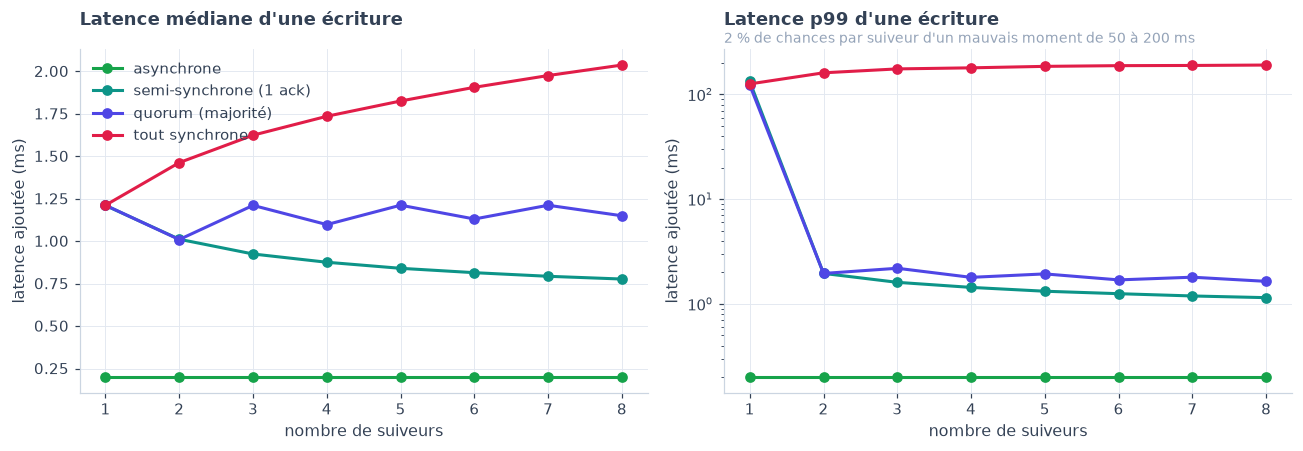

mode,asynchrone,quorum (majorité),semi-synchrone (1 ack),tout synchrone
suiveurs,,,,
1,0.2,123.0,132.7,125.8
2,0.2,2.0,2.0,160.6
4,0.2,1.8,1.4,179.2
8,0.2,1.6,1.1,190.5


In [4]:
def rtt(n, k, rng):
    base = rng.lognormal(np.log(1.0), 0.4, (n, k))
    bad = rng.random((n, k)) < 0.02
    return np.where(bad, rng.uniform(50, 200, (n, k)), base)

modes = {"async": "asynchrone", "semisync": "semi-synchrone (1 ack)", "quorum": "quorum (majorité)",
         "sync": "tout synchrone"}
colors = {"async": GREEN, "semisync": TEAL, "quorum": INDIGO, "sync": ROSE}
ks = range(1, 9)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
rows = []
for m, lab in modes.items():
    p50, p99 = [], []
    for k in ks:
        lat = rp.write_latency_samples(m, k, rtt(40000, k, rng), local=0.2)
        p50.append(np.percentile(lat, 50)); p99.append(np.percentile(lat, 99))
        rows.append({"mode": lab, "suiveurs": k, "p50 (ms)": p50[-1], "p99 (ms)": p99[-1]})
    axes[0].plot(ks, p50, "o-", color=colors[m], label=lab)
    axes[1].plot(ks, p99, "o-", color=colors[m], label=lab)
axes[0].set_title("Latence médiane d'une écriture"); axes[1].set_title("Latence p99 d'une écriture")
for ax in axes:
    ax.set_xlabel("nombre de suiveurs"); ax.set_ylabel("latence ajoutée (ms)")
axes[1].set_yscale("log")
axes[0].legend()
subtitle(axes[1], "2 % de chances par suiveur d'un mauvais moment de 50 à 200 ms")
finish(fig)
plt.show()
pd.DataFrame(rows).pivot(index="suiveurs", columns="mode", values="p99 (ms)").round(1).loc[[1, 2, 4, 8]]

Lecture des courbes :

- la **médiane** bouge peu : attendre le plus lent de 8 suiveurs coûte environ 1 ms de
  plus qu'attendre le plus rapide ;
- le **p99** sépare les modes : en tout synchrone, la probabilité qu'**au moins un**
  suiveur soit lent, $1 - 0{,}98^k$, dépasse toujours 1 % : le centile 99 est dicté par
  le mauvais moment d'un seul suiveur (plus de 50 ms) et empire avec $k$. Le
  semi-synchrone, lui, **profite** de la redondance : il faudrait que tous les suiveurs
  soient lents à la fois ($0{,}02^k$, sous 1 % dès 2 suiveurs). Le quorum est entre les
  deux : avec un seul suiveur, il se confond avec les deux autres modes ;
- l'asynchrone ne paie que l'écriture locale.

Même calcul pour la **disponibilité des écritures** : si chaque suiveur est disponible
avec probabilité $a$, les écritures sont possibles avec probabilité $a^k$ en tout
synchrone, $1-(1-a)^k$ en semi-synchrone (on promeut un autre suiveur synchrone), et
$P(\text{au moins } \lceil k/2 \rceil \text{ sur } k)$ pour un quorum majoritaire.

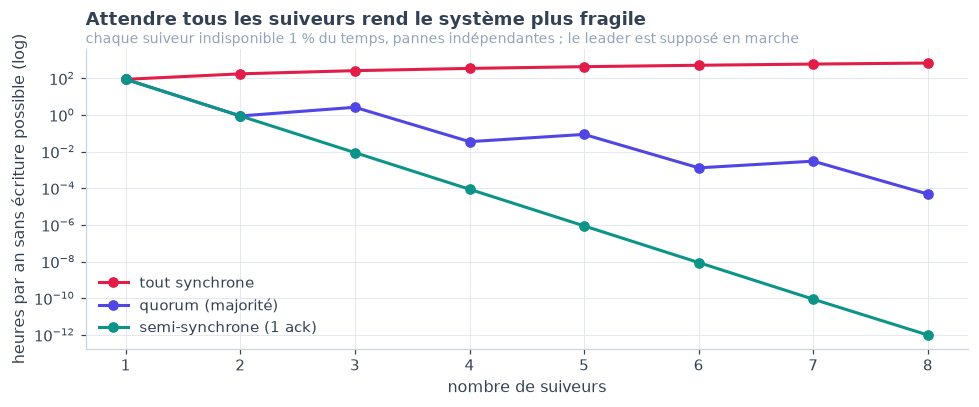

In [5]:
a = 0.99
fig, ax = plt.subplots(figsize=(9, 3.8))
for m, f in {"sync": lambda k: a ** k,
             "quorum": lambda k: rp.k_of_n(a, rp.needed_acks("quorum", k), k),
             "semisync": lambda k: 1 - (1 - a) ** k}.items():
    ax.plot(list(ks), [(1 - f(k)) * 365 * 24 for k in ks], "o-", color=colors[m], label=modes[m])
ax.set_yscale("log")
ax.set_xlabel("nombre de suiveurs"); ax.set_ylabel("heures par an sans écriture possible (log)")
ax.set_title("Attendre tous les suiveurs rend le système plus fragile")
subtitle(ax, "chaque suiveur indisponible 1 % du temps, pannes indépendantes ; le leader est supposé en marche")
ax.legend()
plt.tight_layout(); plt.show()

En tout synchrone, ajouter des suiveurs **dégrade** la disponibilité des écritures (88 h
par an avec un suiveur, plus de 600 h avec huit) ; en semi-synchrone ou par quorum,
chaque suiveur supplémentaire l'améliore. Voilà pourquoi la réplication **totalement
asynchrone** reste très utilisée, surtout avec beaucoup de suiveurs ou des suiveurs
lointains : le leader continue d'écrire même si tous les suiveurs sont à la traîne, au
prix d'une **durabilité affaiblie** (une écriture confirmée peut être perdue, section 5).

> **À retenir.** Synchrone = durabilité, mais latence et disponibilité dictées par les
> suiveurs attendus ; asynchrone = rapide et disponible, mais une écriture confirmée
> peut disparaître avec le leader. Le semi-synchrone (ou un quorum) n'attend que les
> plus rapides : il garde une copie à jour sans dépendre du plus lent.

## 3. Ajouter un suiveur sans arrêter le leader (section *Setting Up New Followers*)

Copier les fichiers de la base ne suffit pas : les clients écrivent pendant la copie, qui
verrait différentes parties de la base à différents instants. Verrouiller la base pendant
la copie irait contre la disponibilité. La recette standard :

1. prendre un **instantané cohérent** du leader, sans le bloquer (c'est aussi ce que
   fait une sauvegarde) ;
2. copier l'instantané sur le nouveau nœud ;
3. le suiveur demande au leader **toutes les modifications depuis l'instantané**, ce qui
   suppose que l'instantané soit associé à une **position exacte** du journal (le *log
   sequence number* de PostgreSQL, les coordonnées de binlog ou les GTID de MySQL) ;
4. une fois l'arriéré appliqué, le suiveur a **rattrapé** le leader et suit le flux.

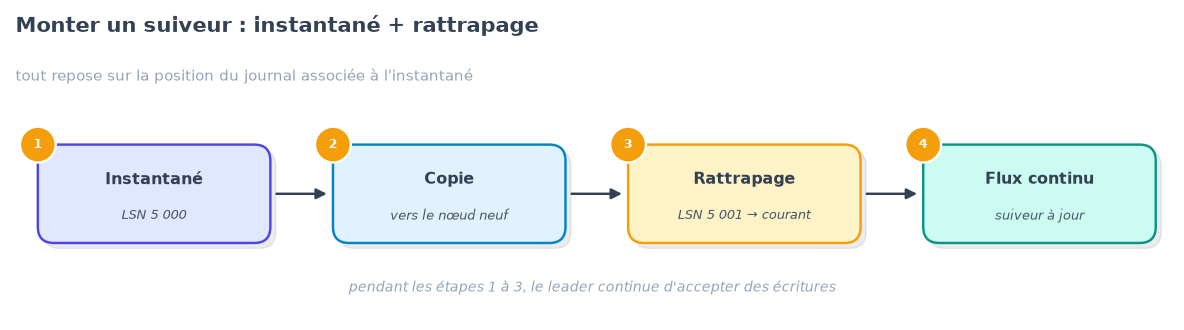

In [6]:
d = Diagram(13, 2.5, title="Monter un suiveur : instantané + rattrapage",
            subtitle="tout repose sur la position du journal associée à l'instantané")
names = d.flow([("s1", "Instantané", "LSN 5 000"), ("s2", "Copie", "vers le nœud neuf"),
                ("s3", "Rattrapage", "LSN 5 001 → courant"), ("s4", "Flux continu", "suiveur à jour")],
               y=1.4, x0=1.6, dx=3.3, colors=[INDIGO, SKY, AMBER, TEAL], w=2.6, h=1.1)
for i, n in enumerate(names):
    d.badge(1.6 + i * 3.3 - 1.3, 1.95, str(i + 1))
d.note(6.5, 0.35, "pendant les étapes 1 à 3, le leader continue d'accepter des écritures", color=GRAY)
d.show()

**Combien de temps dure le rattrapage ?** Pendant la copie (durée $T_c$), le leader
accumule $\lambda T_c$ écritures, où $\lambda$ est son débit d'écriture. Le suiveur les
applique au débit $\mu$ tandis que $\lambda$ nouvelles arrivent chaque seconde : l'arriéré
diminue à la vitesse $\mu - \lambda$, d'où un rattrapage en

$$T_r = \frac{\lambda\, T_c}{\mu - \lambda} = \frac{T_c}{\mu/\lambda - 1}.$$

Si le suiveur n'applique que 10 % plus vite que le leader n'écrit, le rattrapage dure
**dix fois** la copie ; s'il est plus lent ($\mu \le \lambda$), il ne rattrape jamais.

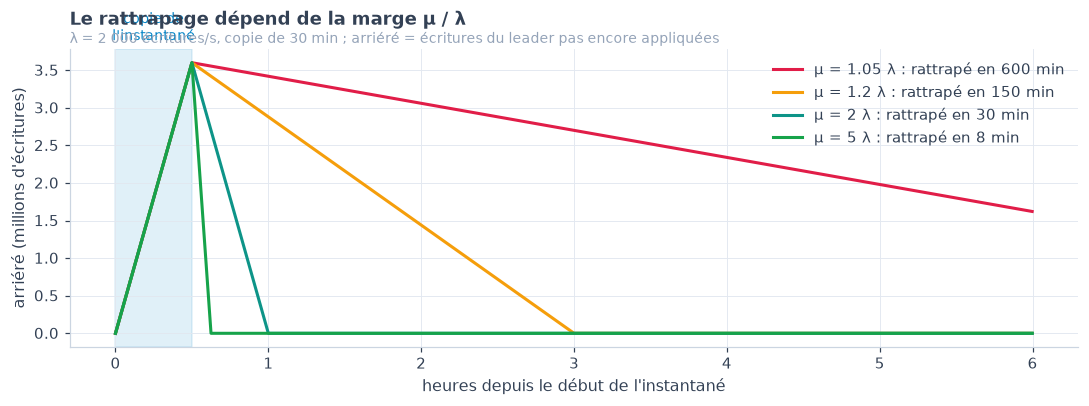

In [7]:
lam, Tc = 2000, 1800                 # 2 000 écritures/s, 30 min de copie
t = np.arange(0, 6 * 3600, 10.0)
fig, ax = plt.subplots(figsize=(10, 3.8))
for ratio, c in [(1.05, ROSE), (1.2, AMBER), (2.0, TEAL), (5.0, GREEN)]:
    mu = ratio * lam
    backlog = np.where(t < Tc, lam * t, np.maximum(0, lam * Tc - (mu - lam) * (t - Tc)))
    Tr = Tc / (ratio - 1)
    ax.plot(t / 3600, backlog / 1e6, color=c, label=f"μ = {ratio:g} λ : rattrapé en {Tr / 60:.0f} min")
ax.axvspan(0, Tc / 3600, color=SKY, alpha=0.12)
ax.text(Tc / 7200, 3.9, "copie de\nl'instantané", ha="center", fontsize=9, color=SKY)
ax.set_xlabel("heures depuis le début de l'instantané"); ax.set_ylabel("arriéré (millions d'écritures)")
ax.set_title("Le rattrapage dépend de la marge μ / λ")
subtitle(ax, "λ = 2 000 écritures/s, copie de 30 min ; arriéré = écritures du leader pas encore appliquées")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

> **À retenir.** Un nouveau suiveur = un instantané cohérent **repéré dans le journal**,
> puis le rejeu de tout ce qui a suivi. Le rattrapage n'est rapide que si le suiveur
> applique nettement plus vite que le leader n'écrit.